# Feature selection
- scRNA-seq datasets contain upto 30,000 genes (depending on the organism) and we have removed genes that are not detected in at least 20 cells. However, many of the remaining genes are not informative and contain mostly zero counts.
- The step of feature selection aims to exclude uninformative genes which might not represent meaningful biological variation across samples.
- Traditional approaches either compute the coefficient of variation (highly variable genes) or the average expression level (highly expressed genes) of all genes to obtain 500-2000 selected genes for downstream analysis. However, these methods are highly sensitive to normalization techniques used before (for e.g., a small pseudo count value close to zero added before log transformation increases the variance of genes with zero counts).
- `deviance` is proposed for feature selection which works on raw counts.
    - Genes with constant expression are described by a multinomial null model.
    - They are approximated by binomial deviance.
    - Highly informative genes across cells will have a high deviance value which indicates a poor fit by the null model.
    - According to the deviance values, the method then ranks all genes and obtains only highly deviant genes.
- deviance is provided within the R package scry.

In [1]:
import logging

import lamindb as ln
import matplotlib.pyplot as plt
import numpy as np
import rpy2.rinterface_lib.callbacks as rcb
import rpy2.robjects as ro
import rpy2.robjects.packages as rpackages
import scanpy as sc
import seaborn as sns
from rpy2.robjects import default_converter, numpy2ri, pandas2ri, r
from rpy2.robjects.conversion import localconverter

# Suppress verbose logging from Scanpy
sc.settings.verbosity = 0

# Set figure parameters for clean, minimal plots
sc.set_figure_params(dpi=80, facecolor="white", frameon=False)

rcb.logger.setLevel(logging.ERROR)

%load_ext rpy2.ipython

ln.connect("theislab/sc-best-practices")

→ connected lamindb: anonymous/intermediate_data
! re-setting django: avoid this by clearing the default instance on the command line via: lamin disconnect
→ connected lamindb: theislab/sc-best-practices
! connected in read-only mode, please use ln.DB("theislab/sc-best-practices") instead


In [2]:
%%R
library(scry)
library(SingleCellExperiment)

Loading required package: SummarizedExperiment
Loading required package: MatrixGenerics
Loading required package: matrixStats

Attaching package: ‘MatrixGenerics’

The following objects are masked from ‘package:matrixStats’:

    colAlls, colAnyNAs, colAnys, colAvgsPerRowSet, colCollapse,
    colCounts, colCummaxs, colCummins, colCumprods, colCumsums,
    colDiffs, colIQRDiffs, colIQRs, colLogSumExps, colMadDiffs,
    colMads, colMaxs, colMeans2, colMedians, colMins, colOrderStats,
    colProds, colQuantiles, colRanges, colRanks, colSdDiffs, colSds,
    colSums2, colTabulates, colVarDiffs, colVars, colWeightedMads,
    colWeightedMeans, colWeightedMedians, colWeightedSds,
    colWeightedVars, rowAlls, rowAnyNAs, rowAnys, rowAvgsPerColSet,
    rowCollapse, rowCounts, rowCummaxs, rowCummins, rowCumprods,
    rowCumsums, rowDiffs, rowIQRDiffs, rowIQRs, rowLogSumExps,
    rowMadDiffs, rowMads, rowMaxs, rowMeans2, rowMedians, rowMins,
    rowOrderStats, rowProds, rowQuantiles, rowRanges, ro

In [3]:
# Loading the already normalized dataset
af = ln.Artifact.connect("theislab/sc-best-practices").get(
    key="preprocessing_visualization/s4d8_normalization.h5ad", is_latest=True
)
adata = af.load()
adata

... synchronizing s4d8_normalization.h5ad: 100.0%


AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells'
    layers: 'analytic_pearson_residuals', 'counts', 'log1p_norm', 'scran_normalization', 'soupX_counts', None (.X)

In [4]:
# Saving the AnnData object in our R environment
X_sparse = adata.X.T.tocoo()

Matrix = rpackages.importr("Matrix")

with localconverter(ro.default_converter + pandas2ri.converter + numpy2ri.converter):
    ro.globalenv["obs"] = adata.obs
    ro.globalenv["var"] = adata.var

i, j = X_sparse.row, X_sparse.col
x = X_sparse.data

ro.globalenv["i"] = ro.IntVector((i + 1).tolist())  # R is 1-indexed
ro.globalenv["j"] = ro.IntVector((j + 1).tolist())
ro.globalenv["x"] = ro.FloatVector(x.tolist())

r("X <- sparseMatrix(i = i, j = j, x = x, dims = c({}, {}))".format(*X_sparse.shape))

In [12]:
# Feature selection with deviance on the non-normalized counts matrix
# The output are the binomial deviance values as a vector
# If several batches are present, it can be passed to the batch argument of devianceFeatureSelection 
# This fits the null model within each batch, so that differences between batches do not make genes look deviant

In [11]:
%%R
sce <- SingleCellExperiment(assays = list(X = X), colData = obs, rowData = var)
sce <- devianceFeatureSelection(sce, assay = "X")

In [13]:
with localconverter(default_converter + pandas2ri.converter + numpy2ri.converter):
    binomial_deviance = ro.r("rowData(sce)$binomial_deviance")

In [18]:
# Sort the binomial deviance vector and select the top 4,000 highly deviant genes
idx = binomial_deviance.argsort()[-4000:]
mask = np.zeros(adata.var_names.shape, dtype=bool)
mask[idx] = True

adata.var["highly_deviant"] = mask
adata.var["binomial_deviance"] = binomial_deviance

In [19]:
# Computing the mean and dispersion for each gene across all cells
sc.pp.highly_variable_genes(adata, layer="scran_normalization")

In [20]:
adata

AnnData object with n_obs × n_vars = 15998 × 20362
    obs: 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_20_genes', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'log1p_total_counts_ribo', 'pct_counts_ribo', 'total_counts_hb', 'log1p_total_counts_hb', 'pct_counts_hb', 'logit_mt_fraction', 'outlier', 'mt_outlier', 'soupx_groups', 'scDblFinder_score', 'scDblFinder_class', 'size_factors'
    var: 'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'ribo', 'hb', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_deviant', 'binomial_deviance', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'hvg'
    layers: 'analytic_pearson_residuals', 'counts', 'log1p_norm', 'scran_normalization', 'soupX_counts', None (.X)

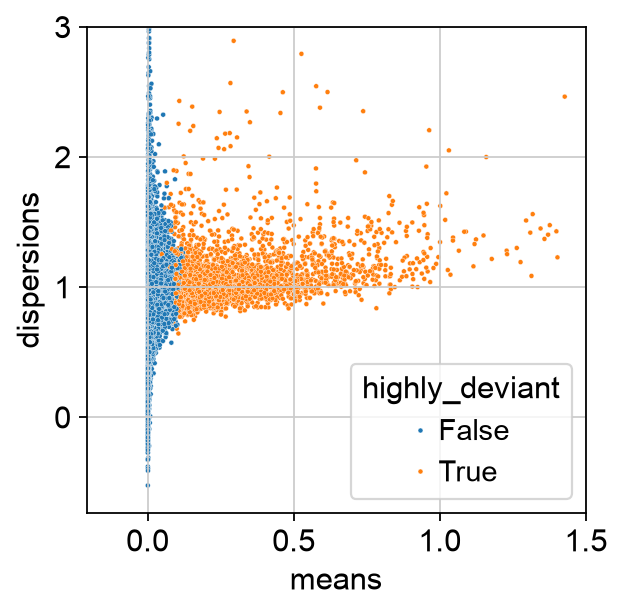

In [21]:
# Visualizing the feature selection results
ax = sns.scatterplot(
    data=adata.var, x="means", y="dispersions", hue="highly_deviant", s=5
)
ax.set_xlim(None, 1.5)
ax.set_ylim(None, 3)
plt.show()

Genes with a high mean expression are selected as highly deviant.

In [23]:
from pathlib import Path

output_dir = Path("../intermediate_data")
output_dir.mkdir(parents=True, exist_ok=True)
output_path = output_dir / "feature_selection.h5ad"

adata.write_h5ad(output_path, compression="gzip")
print(f"Saved dataset after feature selection to: {output_path.resolve()}")

Saved dataset after feature selection to: /Users/ankitmukherjee/Bioinformatics/single_cell_analysis/scverse/05_scRNA_analysis/intermediate_data/feature_selection.h5ad
